# State AI Policy: shared data preparation

Prepare a common table for the supervised and topic analyses. Keep the original records, add cleaned text and readable dates, and inspect the fields before choosing model inputs.

Source: Bhargava and Soliman, [U.S. State AI Legislation Corpus, version 4](https://zenodo.org/records/20781731), `Final_Database_10.csv`. The repository stores this file as `data/raw/Final_Database.csv`.

## 1. Set up

Install the packages in `requirements.txt` once. Open this notebook from the repository root or `josue_src/`.

In [1]:
from pathlib import Path
import sys

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display

project_dir = Path.cwd().parent if Path.cwd().name == "josue_src" else Path.cwd()
sys.path.insert(0, str(project_dir / "josue_src"))
from prepare import prepare_data

source_path = project_dir / "data/raw/Final_Database.csv"
output_path = project_dir / "data/processed/common_intake/common_records.csv"
pd.set_option("display.max_colwidth", 70)

## 2. Prepare and save the table

The script preserves every original field and record. It adds five cleaned text fields, two dates in year-month-day format, and `source_row` for tracing a record back to its position in the source.

Text cleaning standardizes Unicode and whitespace. It keeps case, punctuation, numbers and negation. The script checks that the saved original fields still match the source.

In [2]:
prepared = prepare_data(source_path, output_path)
original_columns = pd.read_csv(source_path, nrows=0).columns

display(pd.DataFrame({
    "Check": ["Source records", "Original fields", "Prepared fields"],
    "Result": [len(prepared), len(original_columns), len(prepared.columns)],
}))

,Check,Result
0,Source records,2571
1,Original fields,29
2,Prepared fields,37


## 3. Compare original and cleaned text

Original text remains available beside its cleaned version. This example shows how line breaks and extra whitespace become a single space without rewriting the bill.

In [3]:
example = prepared.loc[
    prepared["Jurisdiction"].eq("Alabama") & prepared["Bill_Number"].eq("H 208")
].iloc[0]

display(pd.DataFrame({
    "Version": ["Original bill text", "Cleaned bill text"],
    "First 200 characters": [example["Bill_Text"][:200], example["Bill_Text_clean"][:200]],
}))

,Version,First 200 characters
0,Original bill text,HB208 INTRODUCED\nI4K5ZW6-1\nBy Representative Shaw\nRFD: State Go...
1,Cleaned bill text,HB208 INTRODUCED I4K5ZW6-1 By Representative Shaw RFD: State Gover...


## 4. Check text coverage

Bill text, NCSL descriptions, summaries and extracts are separate fields. A blank summary does not mean the bill text is missing. Keep these records in the common table; filtering belongs to the relevant analysis.

In [4]:
text_fields = ["Bill_Text", "NCSL_Summary", "summary", "bill_extracts"]
blank_counts = prepared[text_fields].apply(lambda column: column.str.strip().eq("").sum())
coverage = pd.DataFrame({
    "Populated": len(prepared) - blank_counts,
    "Blank": blank_counts,
})
display(coverage)

both_blank = prepared["summary"].str.strip().eq("") & prepared["bill_extracts"].str.strip().eq("")
print(f"Records with both summary and extract blank: {both_blank.sum():,}")

,Populated,Blank
Bill_Text,2571,0
NCSL_Summary,2571,0
summary,2087,484
bill_extracts,2087,484


Records with both summary and extract blank: 484


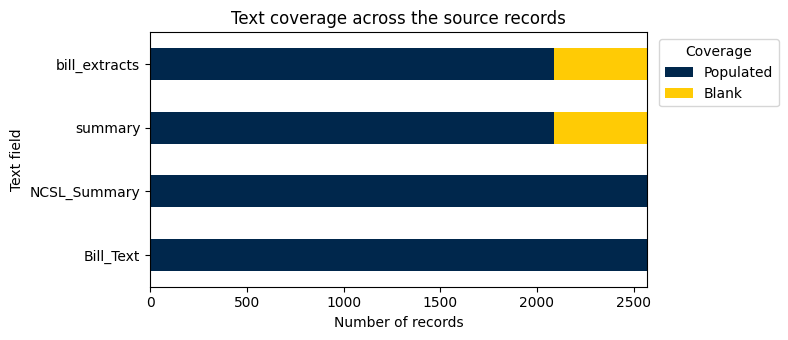

In [5]:
ax = coverage.plot.barh(
    stacked=True, color=["#00274C", "#FFCB05"], figsize=(8, 3.5)
)
ax.set_title("Text coverage across the source records")
ax.set_xlabel("Number of records")
ax.set_ylabel("Text field")
ax.legend(title="Coverage", loc="upper left", bbox_to_anchor=(1.01, 1))
plt.tight_layout()
plt.show()

The same 484 records have blank summaries and extracts. All 2,571 records have populated bill text and NCSL descriptions. These counts describe field coverage; they do not establish text quality.

## 5. Inspect date differences and repeated text

A later bill version can contain information unavailable when the bill was introduced. That matters when deciding what information a prediction model could use. Dates and repeated wording are review cues; this step does not remove records.

In [6]:
introduced = pd.to_datetime(prepared["introduction_date_iso"], format="%Y-%m-%d")
versioned = pd.to_datetime(prepared["version_date_iso"], format="%Y-%m-%d")
repeated_text = prepared["Bill_Text_clean"].duplicated(keep=False) & prepared["Bill_Text_clean"].ne("")

review_counts = pd.Series({
    "Blank bill titles": prepared["Bill_Title_clean"].eq("").sum(),
    "Text version before introduction": versioned.lt(introduced).sum(),
    "Text version after introduction": versioned.gt(introduced).sum(),
    "Records sharing cleaned bill text": repeated_text.sum(),
}, name="Records")
display(review_counts.to_frame())

date_example = prepared.loc[
    prepared["Jurisdiction"].eq("Alaska") & prepared["Bill_Number"].eq("HCR 3"),
    ["source_row", "Bill_Number", "Jurisdiction", "introduction_date_iso", "version_date_iso"],
]
display(date_example)

,Records
Blank bill titles,32
Text version before introduction,13
Text version after introduction,947
Records sharing cleaned bill text,8


,source_row,Bill_Number,Jurisdiction,introduction_date_iso,version_date_iso
7,8,HCR 3,Alaska,2025-02-26,2025-04-11


Alaska HCR 3 was introduced on February 26, 2025, while its text-version date is April 11, 2025. The parsed dates make that gap visible. The team still needs to choose the appropriate text timing for its supervised analysis.

## 6. Use the prepared table

The output is one CSV. `source_row` is the one-based record position in this source snapshot, not a model feature or a verified unique-bill identifier. Read strings explicitly so empty cells and literal values such as `N/A` stay intact.

In [7]:
common = pd.read_csv(output_path, dtype=str, keep_default_na=False)
common[["source_row", "Bill_Number", "Jurisdiction", "Bill_Status", "Bill_Text_clean"]].head()

,source_row,Bill_Number,Jurisdiction,Bill_Status,Bill_Text_clean
0,1,H 208,Alabama,Failed - Adjourned,HB208 INTRODUCED I4K5ZW6-1 By Representative Shaw RFD: State Gover...
1,2,H 365,Alabama,Enacted,"Act No. 2025-449 HB365 By Representatives Collins, Baker Enrolled,..."
2,3,H 515,Alabama,Failed - Adjourned,HB515 INTRODUCED NR3MY8T-1 By Representative Shirey RFD: Insurance...
3,4,H 516,Alabama,Failed - Adjourned,"HB516 INTRODUCED ENNJ229-1 By Representatives Chestnut, Shaw, Lips..."
4,5,H 557,Alabama,Failed - Adjourned,HB557 INTRODUCED HB557 5VL5133-1 By Representative Datcher RFD: In...


Use the `_clean` fields when cleaned text is appropriate. The original fields remain available for comparison. `Bill_Status` and `Bill_Status_Grouped` contain recorded legislative outcomes; lowercase `status` describes the publisher's processing.

David will choose supervised inputs and evaluation. Meng will choose topic inputs and interpretation. This common preparation does not select targets, filter records or fit models.